In [1]:
import matplotlib.pyplot as plt
import sys
sys.path.append('../scripts')
from utils.cftp_func import *

# Test forward bounding chain (one run)

In [2]:
N = 500
d = 4
beta = 0.1
maxiter = 100000
G, couplings = create_ER_graph(N, d, coupling_type='ising')
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(np.float64(0.25541281188299536), np.float64(0.5493061443340548))

In [3]:
nb_star_state, final_step = BC_fwd(beta, G, couplings, sampler=F_beta_Glauber, max_iter=maxiter, init_mode='full_star', lazy=False)

Coalescence achieved at iteration 6485 using full_star initialization.


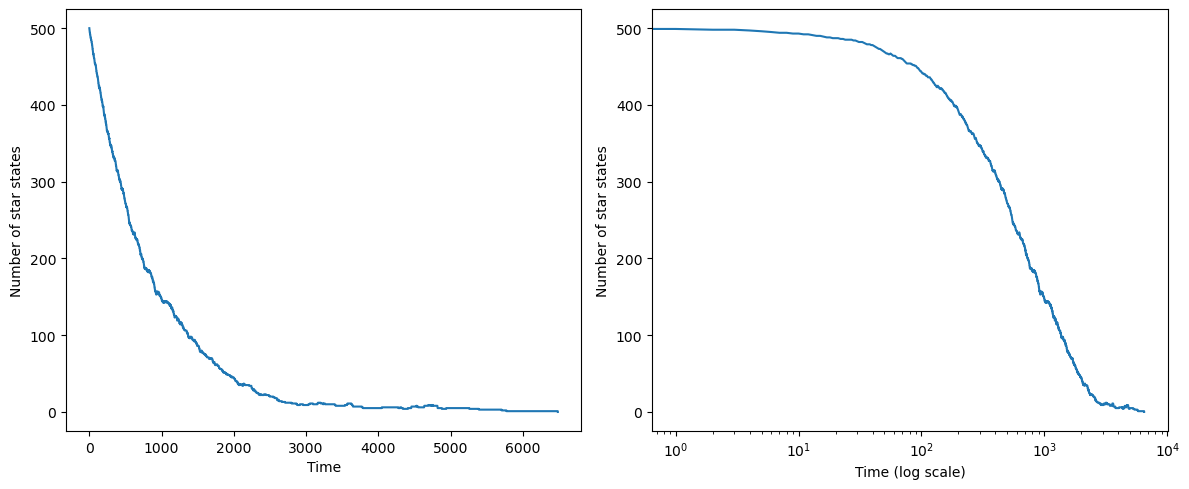

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(nb_star_state)
ax1.set_xlabel('Time')
ax1.set_ylabel('Number of star states')

ax2.plot(nb_star_state)
ax2.set_xscale('log')
ax2.set_xlabel('Time (log scale)')
ax2.set_ylabel('Number of star states')

plt.tight_layout()
plt.show()

# Coalescence times

In [5]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(np.float64(0.25541281188299536), np.float64(0.5493061443340548))

In [29]:
beta = 0.26
coup_type = 'ising'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 10    
nb_itermax = 2**28
print(nb_itermax)
N_list = [100, 250, 500, 1000, 2000, 5000]

268435456


In [30]:
df = compute_coal_time(N_list, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, init_mode='full_star', lazy=False)

Coalescence achieved at iteration 6079 using full_star initialization.
Coalescence achieved at iteration 5256 using full_star initialization.
Coalescence achieved at iteration 11677 using full_star initialization.
Coalescence achieved at iteration 2805 using full_star initialization.
Coalescence achieved at iteration 6864 using full_star initialization.
Coalescence achieved at iteration 11939 using full_star initialization.
Coalescence achieved at iteration 2080 using full_star initialization.
Coalescence achieved at iteration 2157 using full_star initialization.
Coalescence achieved at iteration 27353 using full_star initialization.
Coalescence achieved at iteration 3355 using full_star initialization.
Coalescence achieved at iteration 35538826 using full_star initialization.
Coalescence achieved at iteration 18916 using full_star initialization.
Coalescence achieved at iteration 89183431 using full_star initialization.
Coalescence achieved at iteration 13189 using full_star initializ

In [31]:
import os

csv_path = f"../results/tmp/coal_time_ER_{coup_type}_d{d}.csv"

if os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    df_combined = pd.concat([df_full, df], ignore_index=True)
    df_combined.to_csv(csv_path, index=False)
else:
    df.to_csv(csv_path, index=False)

In [32]:
df = pd.read_csv(csv_path)

print(df['beta'].unique())
print(df['sampler'].unique())
print(df['lazy'].unique())
print(df['init_mode'].unique())
print(df['n_runs'].unique())
print(df['max_iter'].unique())
print(df['N'].unique())
print(len(df))  # total number of rows
df

[0.23 0.24 0.25 0.26]
<StringArray>
['F_beta_Glauber']
Length: 1, dtype: str
[False]
<StringArray>
['full_star']
Length: 1, dtype: str
[10]
[268435456]
[ 100  250  500 1000 2000 5000]
24


,beta,sampler,lazy,init_mode,n_runs,max_iter,N,frac_coal,mean_coal_time,std_coal_time
0,0.23,F_beta_Glauber,False,full_star,10,268435456,100,1.0,2990.2,9.270531e+02
1,0.23,F_beta_Glauber,False,full_star,10,268435456,250,1.0,12478.5,4.910388e+03
2,0.23,F_beta_Glauber,False,full_star,10,268435456,500,1.0,29685.1,1.042829e+04
3,0.23,F_beta_Glauber,False,full_star,10,268435456,1000,1.0,74989.6,2.113352e+04
4,0.23,F_beta_Glauber,False,full_star,10,268435456,2000,1.0,177951.8,4.575539e+04
5,0.23,F_beta_Glauber,False,full_star,10,268435456,5000,1.0,510825.0,1.457862e+05
6,0.24,F_beta_Glauber,False,full_star,10,268435456,100,1.0,4825.8,2.423015e+03
7,0.24,F_beta_Glauber,False,full_star,10,268435456,250,1.0,13102.8,4.788732e+03
8,0.24,F_beta_Glauber,False,full_star,10,268435456,500,1.0,33996.9,1.476471e+04
9,0.24,F_beta_Glauber,False,full_star,10,268435456,1000,1.0,82982.6,4.156760e+04


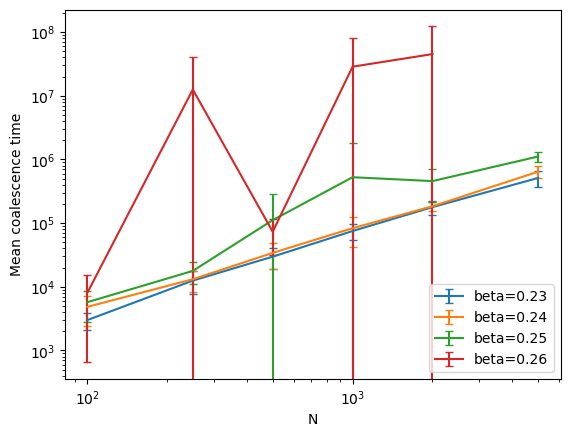

In [33]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['init_mode'] == 'full_star') & 
    (df['n_runs'] == nb_runs) & 
    (df['max_iter'] == nb_itermax) &
    (df['frac_coal'] == 1)
)
df_filtered = df[mask]

betas_to_exclude = []
for beta in df_filtered['beta'].unique():
    if beta in betas_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['beta'] == beta]
    plt.errorbar(sub_df['N'], sub_df['mean_coal_time'],
                yerr=sub_df['std_coal_time'],
                label=f'beta={beta:.2f}',
                capsize=3)

plt.xlabel('N')
plt.ylabel('Mean coalescence time')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

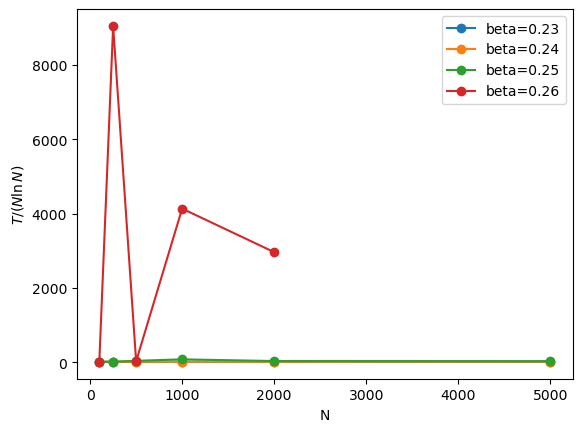

In [34]:
for beta in df_filtered['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    scaling = sub_df['mean_coal_time'].values / (N * np.log(N))
    plt.plot(N, scaling, 'o-', label=f'beta={beta:.2f}')

plt.xlabel('N')
plt.ylabel(r'$T / (N \ln N)$')
plt.legend()
plt.show()

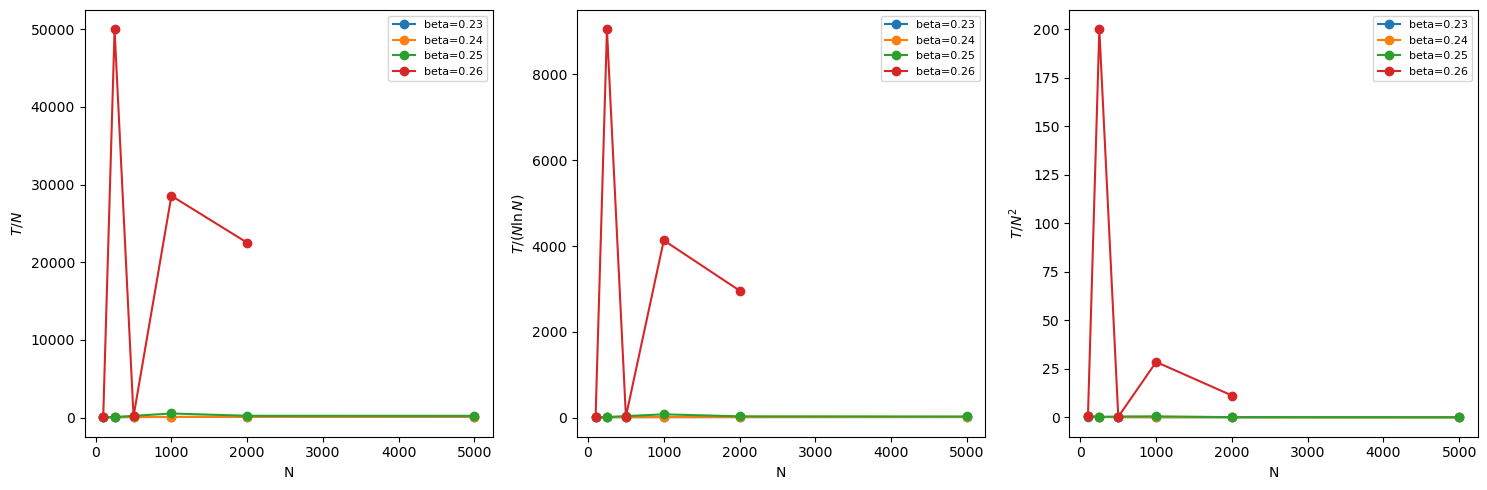

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

scalings = {
    r'$T / N$': lambda N, T: T / N,
    r'$T / (N \ln N)$': lambda N, T: T / (N * np.log(N)),
    r'$T / N^2$': lambda N, T: T / N**2,
}

for ax, (label, scaling_fn) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        ax.plot(N, scaling_fn(N, T), 'o-', label=f'beta={beta:.2f}')
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

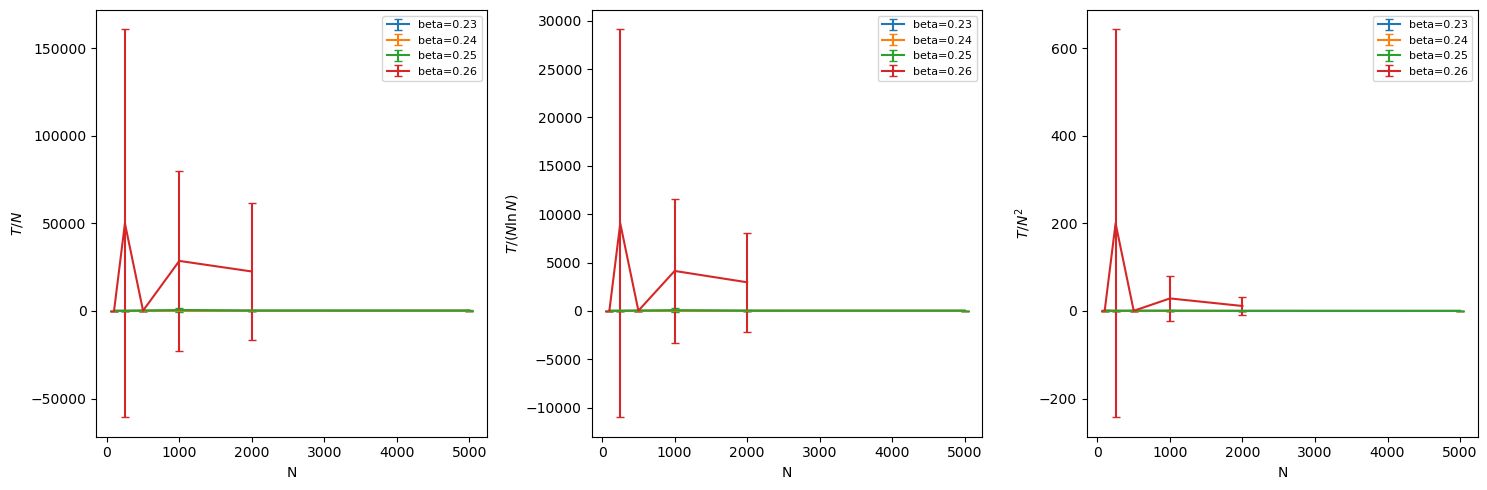

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                 lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    label=f'beta={beta:.2f}', capsize=3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()